# Self-Improving AI - Week 2: Policy Iteration on a Power-Grid MDP

**Domain (same as week 1):** power-grid operations. In week 1 an LLM designed Grid2Op stress scenarios;
here we design a *very small, fully known* MDP for the same domain, an operator recovering a transmission
corridor after line outages, and solve it with dynamic programming.

This notebook re-implements the lecture notebook *Self-Improving AI - Week 2: Policy Iteration*
(Sutton & Barto, Chapter 4) for this MDP:

1. a **SQL schema** for the domain,
2. the **SQLAlchemy** ORM tables for that schema,
3. **policy evaluation** (iterative and exact) and **policy improvement / policy iteration** experiments,
   with value iteration as an independent check.

The main structural difference from Gridworld is that **transitions are stochastic**: a line may be
repaired, another line may trip, and demand may change, so each (state, action) pair has several
successors with probabilities. The schema, the Bellman backups (written as SQL aggregations) and the
exact solver are adapted accordingly.

In [1]:
from typing import Final, Literal, TypeAlias, TypeVar

import numpy as np
import numpy.typing as npt
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from IPython.display import HTML, Markdown, display
from pygments import highlight
from pygments.formatters import HtmlFormatter
from pygments.lexers import get_lexer_by_name
from sqlalchemy import (
    Boolean, Float, ForeignKey, Integer, String, case, create_engine,
    func, insert, literal, select,
)
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, aliased, mapped_column
from sqlalchemy.pool import StaticPool

FloatArray: TypeAlias = npt.NDArray[np.float64]
Algorithm: TypeAlias = Literal[
    "exact_evaluation", "iterative_evaluation", "policy_improvement",
    "policy_iteration", "value_iteration",
]
ValueKind: TypeAlias = Literal[
    "initial", "policy_estimate", "policy_exact", "optimal_estimate",
]

## 0. The MDP

An operator watches a small transmission corridor with **two lines that can fail** (`max_lines_out = 2`).

| Element | Definition |
|---|---|
| **States** | `(lines_out, load)` with `lines_out` in {0, 1, 2} and `load` in {low, high}: 6 operating states, plus one absorbing **BLACKOUT** state |
| **Actions** | `wait` (do nothing), `repair` (dispatch a crew), `redispatch` (shift generation to relieve stressed lines), `shed` (cut some customers' load) |
| **Line repair** | with `repair`, one out-of-service line returns with probability 0.6 |
| **Line trip** | another line trips with probability `base(load) x multiplier(action) x (1 + 0.5 x lines_out)`; base is 0.05 (low load) or 0.25 (high load); `redispatch` halves it and `shed` cuts it to 10% |
| **Blackout** | a trip while 2 lines are already out collapses the corridor (terminal) |
| **Demand** | switches between low and high with probability 0.3 each step, independently of the action |
| **Reward** | `-(action cost) - 1 x lines_out` per step (crew 1, redispatch 2, shedding 6; each open line is a reliability cost), plus a `-100` blackout penalty on the transition into BLACKOUT |
| **Discount** | gamma = 0.95 (a continuing operating task that only ends by blackout) |

Everything below reads the model from SQL; the numbers above are only constructor inputs.

## 1. Data model

The schema follows the lecture's design (model tables, then policy/run/snapshot/value tables), with these
domain changes: `world` becomes `mdp`; states carry `lines_out` and a `load_level` instead of grid cells;
actions carry their cost and effect parameters; and `transition` stores **one row per successor with a
probability**, so its primary key is `(state_id, action_id, next_state_id)`.

In [2]:
SCHEMA_SQL: Final[str] = """
PRAGMA foreign_keys = ON;

CREATE TABLE mdp (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL UNIQUE,
    discount REAL NOT NULL CHECK (discount > 0.0 AND discount < 1.0),
    max_lines_out INTEGER NOT NULL CHECK (max_lines_out >= 1),
    load_switch_probability REAL NOT NULL CHECK (load_switch_probability BETWEEN 0.0 AND 1.0),
    line_cost REAL NOT NULL CHECK (line_cost >= 0.0),
    blackout_penalty REAL NOT NULL CHECK (blackout_penalty <= 0.0)
);

-- Demand regimes shared across MDPs, with the base probability that one more line trips in a step.
CREATE TABLE load_level (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL UNIQUE,
    base_trip_probability REAL NOT NULL CHECK (base_trip_probability BETWEEN 0.0 AND 1.0)
);

-- IDs are database identities, not array offsets. The blackout state has no lines_out / load.
CREATE TABLE state (
    id INTEGER PRIMARY KEY,
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    ordinal INTEGER NOT NULL CHECK (ordinal >= 0),
    lines_out INTEGER CHECK (lines_out >= 0),
    load_level_id INTEGER REFERENCES load_level(id),
    is_terminal INTEGER NOT NULL CHECK (is_terminal IN (0, 1)),
    label TEXT NOT NULL,
    UNIQUE (mdp_id, id),
    UNIQUE (mdp_id, ordinal),
    CHECK (
        (is_terminal = 1 AND lines_out IS NULL AND load_level_id IS NULL)
        OR (is_terminal = 0 AND lines_out IS NOT NULL AND load_level_id IS NOT NULL)
    )
);
CREATE UNIQUE INDEX one_blackout_state_per_mdp ON state(mdp_id) WHERE is_terminal = 1;
CREATE UNIQUE INDEX one_state_per_condition
ON state(mdp_id, lines_out, load_level_id) WHERE is_terminal = 0;

-- Operator actions shared across MDPs, with their cost and effect parameters.
CREATE TABLE action (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL UNIQUE,
    symbol TEXT NOT NULL,
    cost REAL NOT NULL CHECK (cost >= 0.0),
    repair_probability REAL NOT NULL CHECK (repair_probability BETWEEN 0.0 AND 1.0),
    trip_multiplier REAL NOT NULL CHECK (trip_multiplier >= 0.0)
);

-- Stochastic model: one row per possible successor. Probabilities of each (state, action) sum to 1
-- (checked by a query after construction). Blackout is absorbing with reward 0.
CREATE TABLE transition (
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    next_state_id INTEGER NOT NULL,
    probability REAL NOT NULL CHECK (probability > 0.0 AND probability <= 1.0),
    reward REAL NOT NULL,
    PRIMARY KEY (state_id, action_id, next_state_id),
    FOREIGN KEY (mdp_id, state_id) REFERENCES state(mdp_id, id),
    FOREIGN KEY (mdp_id, next_state_id) REFERENCES state(mdp_id, id)
);

CREATE TABLE policy (
    id INTEGER PRIMARY KEY,
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    name TEXT NOT NULL,
    tie_strategy TEXT NOT NULL CHECK (tie_strategy IN ('uniform', 'first', 'given')),
    origin_snapshot_id INTEGER,
    UNIQUE (mdp_id, id),
    FOREIGN KEY (mdp_id, origin_snapshot_id) REFERENCES snapshot(mdp_id, id)
);

CREATE TABLE policy_probability (
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    policy_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    probability REAL NOT NULL CHECK (probability BETWEEN 0.0 AND 1.0),
    PRIMARY KEY (policy_id, state_id, action_id),
    FOREIGN KEY (mdp_id, policy_id) REFERENCES policy(mdp_id, id),
    FOREIGN KEY (mdp_id, state_id) REFERENCES state(mdp_id, id)
);

CREATE TABLE run (
    id INTEGER PRIMARY KEY,
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    name TEXT NOT NULL,
    algorithm TEXT NOT NULL CHECK (algorithm IN (
        'exact_evaluation', 'iterative_evaluation', 'policy_improvement',
        'policy_iteration', 'value_iteration'
    )),
    tolerance REAL NOT NULL CHECK (tolerance > 0.0),
    tie_tolerance REAL NOT NULL CHECK (tie_tolerance >= 0.0),
    max_iterations INTEGER NOT NULL CHECK (max_iterations > 0),
    iterations INTEGER NOT NULL DEFAULT 0 CHECK (iterations >= 0),
    completed_sweeps INTEGER NOT NULL DEFAULT 0 CHECK (completed_sweeps >= 0),
    status TEXT NOT NULL CHECK (status IN ('running', 'converged', 'failed')),
    initial_policy_id INTEGER,
    current_policy_id INTEGER,
    latest_snapshot_id INTEGER,
    reference_snapshot_id INTEGER,
    UNIQUE (mdp_id, id),
    UNIQUE (mdp_id, name),
    FOREIGN KEY (mdp_id, initial_policy_id) REFERENCES policy(mdp_id, id),
    FOREIGN KEY (mdp_id, current_policy_id) REFERENCES policy(mdp_id, id),
    FOREIGN KEY (mdp_id, latest_snapshot_id) REFERENCES snapshot(mdp_id, id),
    FOREIGN KEY (mdp_id, reference_snapshot_id) REFERENCES snapshot(mdp_id, id)
);

CREATE TABLE snapshot (
    id INTEGER PRIMARY KEY,
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    run_id INTEGER NOT NULL,
    sequence INTEGER NOT NULL CHECK (sequence >= 0),
    completed_sweeps INTEGER NOT NULL CHECK (completed_sweeps >= 0),
    value_kind TEXT NOT NULL CHECK (value_kind IN (
        'initial', 'policy_estimate', 'policy_exact', 'optimal_estimate'
    )),
    target_policy_id INTEGER,
    greedy_policy_id INTEGER,
    policy_residual REAL CHECK (policy_residual >= 0.0),
    optimality_residual REAL CHECK (optimality_residual >= 0.0),
    changed_policy_states INTEGER CHECK (changed_policy_states >= 0),
    UNIQUE (mdp_id, id),
    UNIQUE (run_id, sequence),
    FOREIGN KEY (mdp_id, run_id) REFERENCES run(mdp_id, id),
    FOREIGN KEY (mdp_id, target_policy_id) REFERENCES policy(mdp_id, id),
    FOREIGN KEY (mdp_id, greedy_policy_id) REFERENCES policy(mdp_id, id),
    CHECK (
        (value_kind IN ('policy_estimate', 'policy_exact') AND target_policy_id IS NOT NULL)
        OR value_kind IN ('initial', 'optimal_estimate')
    )
);

CREATE TABLE state_value (
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    snapshot_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    value REAL NOT NULL,
    PRIMARY KEY (snapshot_id, state_id),
    FOREIGN KEY (mdp_id, snapshot_id) REFERENCES snapshot(mdp_id, id),
    FOREIGN KEY (mdp_id, state_id) REFERENCES state(mdp_id, id)
);

-- Materialized q_v(s,a) = sum_s' p(s'|s,a) [r + gamma v(s')], computed from each snapshot.
CREATE TABLE action_value (
    mdp_id INTEGER NOT NULL REFERENCES mdp(id),
    snapshot_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    value REAL NOT NULL,
    PRIMARY KEY (snapshot_id, state_id, action_id),
    FOREIGN KEY (mdp_id, snapshot_id) REFERENCES snapshot(mdp_id, id),
    FOREIGN KEY (mdp_id, state_id) REFERENCES state(mdp_id, id)
);
"""

display(HTML(highlight(SCHEMA_SQL, get_lexer_by_name("sql"),
                       HtmlFormatter(noclasses=True, cssclass="", style="default"))))

In [3]:
engine = create_engine("sqlite+pysqlite:///:memory:", poolclass=StaticPool)
with engine.begin() as connection:
    for statement in SCHEMA_SQL.split(";"):
        if statement.strip():
            connection.exec_driver_sql(statement)

### One set of Python models

These SQLAlchemy ORM classes map the schema's columns; SQL creates and constrains the tables.

In [4]:
class Base(DeclarativeBase):
    pass


_ModelT = TypeVar("_ModelT", bound=Base)


def store(db: Session, model: _ModelT) -> _ModelT:
    db.add(model)
    db.flush()
    return model


class MDP(Base):
    __tablename__ = "mdp"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    name: Mapped[str] = mapped_column(String)
    discount: Mapped[float] = mapped_column(Float)
    max_lines_out: Mapped[int] = mapped_column(Integer)
    load_switch_probability: Mapped[float] = mapped_column(Float)
    line_cost: Mapped[float] = mapped_column(Float)
    blackout_penalty: Mapped[float] = mapped_column(Float)


class LoadLevel(Base):
    __tablename__ = "load_level"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    name: Mapped[str] = mapped_column(String)
    base_trip_probability: Mapped[float] = mapped_column(Float)


class State(Base):
    __tablename__ = "state"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    ordinal: Mapped[int] = mapped_column(Integer)
    lines_out: Mapped[int | None] = mapped_column(Integer)
    load_level_id: Mapped[int | None] = mapped_column(ForeignKey("load_level.id"))
    is_terminal: Mapped[bool] = mapped_column(Boolean)
    label: Mapped[str] = mapped_column(String)


class Action(Base):
    __tablename__ = "action"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    name: Mapped[str] = mapped_column(String)
    symbol: Mapped[str] = mapped_column(String)
    cost: Mapped[float] = mapped_column(Float)
    repair_probability: Mapped[float] = mapped_column(Float)
    trip_multiplier: Mapped[float] = mapped_column(Float)


class Transition(Base):
    __tablename__ = "transition"
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    next_state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    probability: Mapped[float] = mapped_column(Float)
    reward: Mapped[float] = mapped_column(Float)


class Policy(Base):
    __tablename__ = "policy"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    name: Mapped[str] = mapped_column(String)
    tie_strategy: Mapped[str] = mapped_column(String)
    origin_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))


class PolicyProbability(Base):
    __tablename__ = "policy_probability"
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    policy_id: Mapped[int] = mapped_column(ForeignKey("policy.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    probability: Mapped[float] = mapped_column(Float)


class Run(Base):
    __tablename__ = "run"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    name: Mapped[str] = mapped_column(String)
    algorithm: Mapped[str] = mapped_column(String)
    tolerance: Mapped[float] = mapped_column(Float)
    tie_tolerance: Mapped[float] = mapped_column(Float)
    max_iterations: Mapped[int] = mapped_column(Integer)
    iterations: Mapped[int] = mapped_column(Integer)
    completed_sweeps: Mapped[int] = mapped_column(Integer)
    status: Mapped[str] = mapped_column(String)
    initial_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    current_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    latest_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))
    reference_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))


class Snapshot(Base):
    __tablename__ = "snapshot"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    run_id: Mapped[int] = mapped_column(ForeignKey("run.id"))
    sequence: Mapped[int] = mapped_column(Integer)
    completed_sweeps: Mapped[int] = mapped_column(Integer)
    value_kind: Mapped[str] = mapped_column(String)
    target_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    greedy_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    policy_residual: Mapped[float | None] = mapped_column(Float)
    optimality_residual: Mapped[float | None] = mapped_column(Float)
    changed_policy_states: Mapped[int | None] = mapped_column(Integer)


class StateValue(Base):
    __tablename__ = "state_value"
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    snapshot_id: Mapped[int] = mapped_column(ForeignKey("snapshot.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    value: Mapped[float] = mapped_column(Float)


class ActionValue(Base):
    __tablename__ = "action_value"
    mdp_id: Mapped[int] = mapped_column(ForeignKey("mdp.id"))
    snapshot_id: Mapped[int] = mapped_column(ForeignKey("snapshot.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    value: Mapped[float] = mapped_column(Float)

## 2. Create the MDP in SQL

The constructor writes the complete model in one transaction. For each operating state and action it
enumerates the independent outcomes (repair or not, trip or not, demand stays or switches), merges outcomes
that reach the same successor, and stores one `transition` row per successor. After creation, every
algorithm reads the model only from SQL.

In [5]:
def create_mdp(
    db: Session,
    name: str,
    *,
    discount: float = 0.95,
    max_lines_out: int = 2,
    load_switch_probability: float = 0.3,
    line_cost: float = 1.0,
    blackout_penalty: float = -100.0,
) -> MDP:
    mdp = store(db, MDP(
        name=name, discount=discount, max_lines_out=max_lines_out,
        load_switch_probability=load_switch_probability, line_cost=line_cost,
        blackout_penalty=blackout_penalty,
    ))
    levels = list(db.scalars(select(LoadLevel).order_by(LoadLevel.id)))
    states: dict[tuple[int, int], State] = {}
    ordinal = 0
    for lines_out in range(max_lines_out + 1):
        for level in levels:
            states[(lines_out, level.id)] = store(db, State(
                mdp_id=mdp.id, ordinal=ordinal, lines_out=lines_out, load_level_id=level.id,
                is_terminal=False, label=f"{lines_out} out / {level.name}",
            ))
            ordinal += 1
    blackout = store(db, State(mdp_id=mdp.id, ordinal=ordinal, lines_out=None, load_level_id=None,
                               is_terminal=True, label="BLACKOUT"))
    actions = list(db.scalars(select(Action).order_by(Action.id)))
    for (lines_out, level_id), state in states.items():
        level = db.get(LoadLevel, level_id)
        assert level is not None
        for action in actions:
            p_repair = action.repair_probability if lines_out > 0 else 0.0
            p_trip = min(1.0, level.base_trip_probability * action.trip_multiplier
                         * (1.0 + 0.5 * lines_out))
            step_reward = -action.cost - line_cost * lines_out
            successors: dict[int, list[float]] = {}  # next_state_id -> [probability, reward]
            for repaired, p_r in ((1, p_repair), (0, 1.0 - p_repair)):
                for tripped, p_t in ((1, p_trip), (0, 1.0 - p_trip)):
                    for next_level in levels:
                        p_l = (1.0 - load_switch_probability if next_level.id == level_id
                               else load_switch_probability / (len(levels) - 1))
                        probability = p_r * p_t * p_l
                        if probability <= 0.0:
                            continue
                        next_lines = lines_out - repaired + tripped
                        if next_lines > max_lines_out:
                            next_state, reward = blackout, step_reward + blackout_penalty
                        else:
                            next_state, reward = states[(next_lines, next_level.id)], step_reward
                        entry = successors.setdefault(next_state.id, [0.0, reward])
                        entry[0] += probability
            for next_state_id, (probability, reward) in successors.items():
                store(db, Transition(
                    mdp_id=mdp.id, state_id=state.id, action_id=action.id,
                    next_state_id=next_state_id, probability=probability, reward=reward,
                ))
    for action in actions:
        store(db, Transition(mdp_id=mdp.id, state_id=blackout.id, action_id=action.id,
                             next_state_id=blackout.id, probability=1.0, reward=0.0))
    db.flush()
    return mdp


def validate_model(db: Session, mdp: MDP) -> None:
    # Every (state, action) distribution must sum to one.
    totals = db.execute(
        select(Transition.state_id, Transition.action_id, func.sum(Transition.probability))
        .where(Transition.mdp_id == mdp.id)
        .group_by(Transition.state_id, Transition.action_id)
    ).all()
    bad = [row for row in totals if abs(row[2] - 1.0) > 1e-12]
    if bad:
        raise ValueError(f"Probabilities do not sum to 1: {bad}")


def make_policy(db: Session, mdp: MDP, name: str, choice: dict[str, float] | None = None) -> Policy:
    # choice=None: uniform random policy; otherwise fixed action probabilities in every state.
    policy = store(db, Policy(mdp_id=mdp.id, name=name, tie_strategy="given"))
    actions = list(db.scalars(select(Action).order_by(Action.id)))
    weights = choice or {a.name: 1.0 / len(actions) for a in actions}
    for state in db.scalars(select(State).where(State.mdp_id == mdp.id)):
        for action in actions:
            store(db, PolicyProbability(
                mdp_id=mdp.id, policy_id=policy.id, state_id=state.id, action_id=action.id,
                probability=weights.get(action.name, 0.0),
            ))
    db.flush()
    return policy


with Session(engine) as db:
    db.add_all([
        LoadLevel(id=0, name="low", base_trip_probability=0.05),
        LoadLevel(id=1, name="high", base_trip_probability=0.25),
        Action(id=0, name="wait", symbol="W", cost=0.0, repair_probability=0.0, trip_multiplier=1.0),
        Action(id=1, name="repair", symbol="R", cost=1.0, repair_probability=0.6, trip_multiplier=1.0),
        Action(id=2, name="redispatch", symbol="D", cost=2.0, repair_probability=0.0, trip_multiplier=0.5),
        Action(id=3, name="shed", symbol="S", cost=6.0, repair_probability=0.0, trip_multiplier=0.1),
    ])
    db.commit()

### Configure the main MDP

Change the constructor arguments to explore other settings (for example a larger `max_lines_out` or a
different `blackout_penalty`). The rest of the notebook derives states, policies and plots from SQL.

In [6]:
with Session(engine) as db:
    main_mdp = create_mdp(db, name="main")
    validate_model(db, main_mdp)
    make_policy(db, main_mdp, "uniform")
    make_policy(db, main_mdp, "always wait", {"wait": 1.0})
    db.commit()
    n_states = db.scalar(select(func.count()).select_from(State).where(State.mdp_id == main_mdp.id))
    n_rows = db.scalar(select(func.count()).select_from(Transition).where(Transition.mdp_id == main_mdp.id))
    print(f"{n_states} states, {n_rows} transition rows; every (state, action) distribution sums to 1")

    # Show one row of the model: the successors of (2 out / high) under each action.
    s = db.scalars(select(State).where(State.mdp_id == main_mdp.id, State.label == "2 out / high")).one()
    nxt = aliased(State)
    rows = db.execute(
        select(Action.name, nxt.label, Transition.probability, Transition.reward)
        .join(Action, Action.id == Transition.action_id)
        .join(nxt, nxt.id == Transition.next_state_id)
        .where(Transition.state_id == s.id)
        .order_by(Action.id, nxt.ordinal)
    ).all()
    table = "| action | next state | p | reward |\n|---|---|---:|---:|\n" + "\n".join(
        f"| {a} | {n} | {p:.3f} | {r:.1f} |" for a, n, p, r in rows)
    display(Markdown("**Successors of `2 out / high`:**\n\n" + table))

7 states, 100 transition rows; every (state, action) distribution sums to 1


**Successors of `2 out / high`:**

| action | next state | p | reward |
|---|---|---:|---:|
| wait | 2 out / low | 0.150 | -2.0 |
| wait | 2 out / high | 0.350 | -2.0 |
| wait | BLACKOUT | 0.500 | -102.0 |
| repair | 1 out / low | 0.090 | -3.0 |
| repair | 1 out / high | 0.210 | -3.0 |
| repair | 2 out / low | 0.150 | -3.0 |
| repair | 2 out / high | 0.350 | -3.0 |
| repair | BLACKOUT | 0.200 | -103.0 |
| redispatch | 2 out / low | 0.225 | -4.0 |
| redispatch | 2 out / high | 0.525 | -4.0 |
| redispatch | BLACKOUT | 0.250 | -104.0 |
| shed | 2 out / low | 0.285 | -8.0 |
| shed | 2 out / high | 0.665 | -8.0 |
| shed | BLACKOUT | 0.050 | -108.0 |

## 3. Bellman operations

As in the lecture, a `Run` holds settings and live state, and each `Snapshot` is a complete value table.
Backups insert new snapshots directly from SQL. Because transitions are stochastic, the one-step lookahead is
an **expectation over successors**:

$$q_v(s,a) = \sum_{s'} p(s' \mid s,a)\,\big[r(s,a,s') + \gamma\, v(s')\big],$$

computed by a `GROUP BY (state, action)` aggregation over the `transition` table.

In [7]:
def new_run(
    db: Session,
    mdp: MDP,
    name: str,
    algorithm: Algorithm,
    policy: Policy | None = None,
    reference: Snapshot | None = None,
    *,
    tolerance: float = 1e-9,
    max_iterations: int = 10_000,
) -> Run:
    return store(db, Run(
        mdp_id=mdp.id, name=name, algorithm=algorithm, tolerance=tolerance,
        tie_tolerance=1e-10, max_iterations=max_iterations, iterations=0, completed_sweeps=0,
        status="running", initial_policy_id=None if policy is None else policy.id,
        current_policy_id=None if policy is None else policy.id,
        reference_snapshot_id=None if reference is None else reference.id,
    ))


def new_snapshot(db: Session, run: Run, value_kind: ValueKind, policy: Policy | None = None) -> Snapshot:
    last = db.scalar(select(func.max(Snapshot.sequence)).where(Snapshot.run_id == run.id))
    return store(db, Snapshot(
        mdp_id=run.mdp_id, run_id=run.id, sequence=0 if last is None else int(last) + 1,
        completed_sweeps=run.completed_sweeps, value_kind=value_kind,
        target_policy_id=None if policy is None else policy.id,
    ))


def finish_snapshot(db: Session, run: Run, snapshot: Snapshot) -> Snapshot:
    # Materialize q_v (expected over successors) and the residuals from stored state values.
    target = func.sum(Transition.probability * (Transition.reward + MDP.discount * StateValue.value))
    statement = (
        select(literal(run.mdp_id), literal(snapshot.id), Transition.state_id,
               Transition.action_id, target)
        .select_from(Transition)
        .join(MDP, MDP.id == Transition.mdp_id)
        .join(StateValue, StateValue.state_id == Transition.next_state_id)
        .where(Transition.mdp_id == run.mdp_id, StateValue.snapshot_id == snapshot.id)
        .group_by(Transition.state_id, Transition.action_id)
    )
    db.execute(insert(ActionValue).from_select(
        ["mdp_id", "snapshot_id", "state_id", "action_id", "value"], statement))
    best = (
        select(ActionValue.state_id, func.max(ActionValue.value).label("target"))
        .where(ActionValue.snapshot_id == snapshot.id)
        .group_by(ActionValue.state_id).subquery()
    )
    snapshot.optimality_residual = float(db.scalar(
        select(func.max(func.abs(best.c.target - StateValue.value)))
        .join(best, best.c.state_id == StateValue.state_id)
        .where(StateValue.snapshot_id == snapshot.id)) or 0.0)
    if snapshot.target_policy_id is not None:
        expected = (
            select(ActionValue.state_id,
                   func.sum(PolicyProbability.probability * ActionValue.value).label("target"))
            .join(PolicyProbability, (PolicyProbability.state_id == ActionValue.state_id)
                  & (PolicyProbability.action_id == ActionValue.action_id))
            .where(ActionValue.snapshot_id == snapshot.id,
                   PolicyProbability.policy_id == snapshot.target_policy_id)
            .group_by(ActionValue.state_id).subquery()
        )
        snapshot.policy_residual = float(db.scalar(
            select(func.max(func.abs(expected.c.target - StateValue.value)))
            .join(expected, expected.c.state_id == StateValue.state_id)
            .where(StateValue.snapshot_id == snapshot.id)) or 0.0)
    run.latest_snapshot_id = snapshot.id
    db.flush()
    return snapshot


def initialize_values(db: Session, run: Run) -> Snapshot:
    snapshot = new_snapshot(db, run, "initial")
    db.execute(insert(StateValue).from_select(
        ["mdp_id", "snapshot_id", "state_id", "value"],
        select(literal(run.mdp_id), literal(snapshot.id), State.id, literal(0.0))
        .where(State.mdp_id == run.mdp_id)))
    return finish_snapshot(db, run, snapshot)


def backup(db: Session, run: Run, previous: Snapshot, policy: Policy | None = None) -> Snapshot:
    # Policy expectation (evaluation) or action maximum (value iteration), from stored q-values.
    run.completed_sweeps += 1
    snapshot = new_snapshot(db, run, "optimal_estimate" if policy is None else "policy_estimate", policy)
    if policy is None:
        rows = (select(literal(run.mdp_id), literal(snapshot.id), ActionValue.state_id,
                       func.max(ActionValue.value))
                .where(ActionValue.snapshot_id == previous.id)
                .group_by(ActionValue.state_id))
    else:
        rows = (select(literal(run.mdp_id), literal(snapshot.id), ActionValue.state_id,
                       func.sum(PolicyProbability.probability * ActionValue.value))
                .join(PolicyProbability, (PolicyProbability.state_id == ActionValue.state_id)
                      & (PolicyProbability.action_id == ActionValue.action_id))
                .where(ActionValue.snapshot_id == previous.id,
                       PolicyProbability.policy_id == policy.id)
                .group_by(ActionValue.state_id))
    db.execute(insert(StateValue).from_select(["mdp_id", "snapshot_id", "state_id", "value"], rows))
    return finish_snapshot(db, run, snapshot)


def greedify(db: Session, run: Run, snapshot: Snapshot, *, split_ties: bool = True) -> Policy:
    policy = store(db, Policy(mdp_id=run.mdp_id, name=f"greedy from snapshot {snapshot.id}",
                              tie_strategy="uniform" if split_ties else "first",
                              origin_snapshot_id=snapshot.id))
    best = (select(ActionValue.state_id, func.max(ActionValue.value).label("best"))
            .where(ActionValue.snapshot_id == snapshot.id)
            .group_by(ActionValue.state_id).subquery())
    is_max = ActionValue.value >= best.c.best - run.tie_tolerance
    if split_ties:
        count = func.sum(case((is_max, 1), else_=0)).over(partition_by=ActionValue.state_id)
        probability = case((is_max, 1.0 / count), else_=0.0)
    else:
        first = func.min(case((is_max, ActionValue.action_id))).over(partition_by=ActionValue.state_id)
        probability = case((ActionValue.action_id == first, 1.0), else_=0.0)
    db.execute(insert(PolicyProbability).from_select(
        ["mdp_id", "policy_id", "state_id", "action_id", "probability"],
        select(literal(run.mdp_id), literal(policy.id), ActionValue.state_id,
               ActionValue.action_id, probability)
        .join(best, best.c.state_id == ActionValue.state_id)
        .where(ActionValue.snapshot_id == snapshot.id)))
    snapshot.greedy_policy_id = policy.id
    db.flush()
    return policy

## 4. Policy evaluation

The iterative evaluator only writes SQL snapshots. The exact evaluator solves the linear system
$(I - \gamma P_\pi)\,v = r_\pi$ over the operating (non-terminal) states, with an explicit mapping from
database state IDs to matrix indices; the blackout state's value is 0 because it is absorbing with zero
reward. Unlike the lecture's Gridworld (gamma = 1), the discount here makes the system non-singular for every
policy, including ones that never reach the terminal state.

In [8]:
def evaluate_iteratively(db: Session, run: Run, policy: Policy) -> Snapshot:
    snapshot = initialize_values(db, run)
    for iteration in range(1, run.max_iterations + 1):
        run.iterations = iteration
        snapshot = backup(db, run, snapshot, policy)
        assert snapshot.policy_residual is not None
        if snapshot.policy_residual <= run.tolerance:
            run.status = "converged"
            db.flush()
            return snapshot
    run.status = "failed"
    db.flush()
    raise RuntimeError("Evaluation exceeded the run's stored iteration limit.")


def evaluate_exactly(db: Session, run: Run, policy: Policy) -> Snapshot:
    mdp = db.get(MDP, run.mdp_id)
    assert mdp is not None
    active_ids = list(db.scalars(select(State.id).where(State.mdp_id == run.mdp_id, ~State.is_terminal)
                                 .order_by(State.ordinal)))
    index = {state_id: i for i, state_id in enumerate(active_ids)}
    n = len(active_ids)
    coefficients: FloatArray = np.eye(n, dtype=np.float64)
    rewards: FloatArray = np.zeros(n, dtype=np.float64)
    statement = (
        select(Transition, PolicyProbability.probability)
        .join(PolicyProbability, (PolicyProbability.state_id == Transition.state_id)
              & (PolicyProbability.action_id == Transition.action_id))
        .where(Transition.mdp_id == run.mdp_id, PolicyProbability.policy_id == policy.id)
    )
    for transition, pi in db.execute(statement):
        if transition.state_id not in index:
            continue
        row = index[transition.state_id]
        weight = pi * transition.probability
        rewards[row] += weight * transition.reward
        if transition.next_state_id in index:
            coefficients[row, index[transition.next_state_id]] -= mdp.discount * weight
    solution = np.linalg.solve(coefficients, rewards)
    snapshot = new_snapshot(db, run, "policy_exact", policy)
    for state in db.scalars(select(State).where(State.mdp_id == run.mdp_id)):
        value = 0.0 if state.is_terminal else float(solution[index[state.id]])
        store(db, StateValue(mdp_id=run.mdp_id, snapshot_id=snapshot.id, state_id=state.id, value=value))
    db.flush()
    return finish_snapshot(db, run, snapshot)

In [9]:
with Session(engine) as db:
    mdp = db.scalars(select(MDP).where(MDP.name == "main")).one()
    for policy_name in ("uniform", "always wait"):
        policy = db.scalars(select(Policy).where(Policy.mdp_id == mdp.id, Policy.name == policy_name)).one()
        reference_run = new_run(db, mdp, f"{policy_name} reference", "exact_evaluation", policy)
        reference = evaluate_exactly(db, reference_run, policy)
        reference_run.status = "converged"
        evaluation_run = new_run(db, mdp, f"{policy_name} evaluation", "iterative_evaluation", policy, reference)
        evaluate_iteratively(db, evaluation_run, policy)
    db.commit()

### Query and plot the recorded values

The operating states form a small 2-D grid (demand level x number of lines out), so values are drawn as a
heatmap like the lecture's Gridworld, with the blackout state as an extra column. Letters show the greedy
action(s) with respect to the displayed values: **W**ait, **R**epair, re**D**ispatch, **S**hed.

In [10]:
def latest_snapshot(db: Session, run: Run) -> Snapshot:
    assert run.latest_snapshot_id is not None
    snapshot = db.get(Snapshot, run.latest_snapshot_id)
    assert snapshot is not None
    return snapshot


def find_run(db: Session, mdp: MDP, name: str) -> Run:
    return db.scalars(select(Run).where(Run.mdp_id == mdp.id, Run.name == name)).one()


def values_by_label(db: Session, snapshot: Snapshot) -> dict[str, float]:
    return dict(db.execute(
        select(State.label, StateValue.value).join(StateValue, StateValue.state_id == State.id)
        .where(StateValue.snapshot_id == snapshot.id).order_by(State.ordinal)).all())


def greedy_symbols(db: Session, policy_id: int, state_id: int) -> str:
    return "".join(db.scalars(
        select(Action.symbol).join(PolicyProbability, PolicyProbability.action_id == Action.id)
        .where(PolicyProbability.policy_id == policy_id, PolicyProbability.state_id == state_id,
               PolicyProbability.probability > 0.0).order_by(Action.id)))


def draw_snapshot(db: Session, axis: Axes, snapshot: Snapshot, title: str, vmin: float = -60.0) -> None:
    mdp = db.get(MDP, snapshot.mdp_id)
    assert mdp is not None
    levels = list(db.scalars(select(LoadLevel).order_by(LoadLevel.id)))
    grid = np.full((len(levels), mdp.max_lines_out + 2), np.nan)
    rows = db.execute(
        select(State, StateValue.value).join(StateValue, StateValue.state_id == State.id)
        .where(StateValue.snapshot_id == snapshot.id)).all()
    for state, value in rows:
        if state.is_terminal:
            grid[:, -1] = value
        else:
            grid[levels.index(db.get(LoadLevel, state.load_level_id)), state.lines_out] = value
    axis.imshow(grid, cmap="RdYlGn", vmin=vmin, vmax=0.0, aspect="auto")
    for state, value in rows:
        if state.is_terminal:
            axis.text(mdp.max_lines_out + 1, (len(levels) - 1) / 2, "BLACKOUT\n0", ha="center",
                      va="center", fontsize=9)
            continue
        r = levels.index(db.get(LoadLevel, state.load_level_id))
        label = f"{value:.1f}"
        if snapshot.greedy_policy_id is not None:
            label += "\n" + greedy_symbols(db, snapshot.greedy_policy_id, state.id)
        axis.text(state.lines_out, r, label, ha="center", va="center", fontsize=9)
    axis.set_xticks(range(mdp.max_lines_out + 2),
                    [f"{k} out" for k in range(mdp.max_lines_out + 1)] + ["terminal"])
    axis.set_yticks(range(len(levels)), [f"{lvl.name} load" for lvl in levels])
    axis.set_title(title)


def error_query(db: Session, run: Run) -> list[tuple[int, float]]:
    assert run.reference_snapshot_id is not None
    reference = aliased(StateValue)
    statement = (
        select(Snapshot.completed_sweeps, func.max(func.abs(StateValue.value - reference.value)))
        .join(StateValue, StateValue.snapshot_id == Snapshot.id)
        .join(reference, reference.state_id == StateValue.state_id)
        .where(Snapshot.run_id == run.id, reference.snapshot_id == run.reference_snapshot_id)
        .group_by(Snapshot.id).order_by(Snapshot.sequence))
    return [(sweeps, float(error)) for sweeps, error in db.execute(statement)]


def new_figure(width: float, height: float) -> Figure:
    return plt.figure(figsize=(width, height), dpi=110, layout="constrained")

**Look for:** how the iterative estimates of the uniform-random policy approach the linear-solve reference
sweep by sweep, and how quickly the greedy letters settle compared with the values themselves.

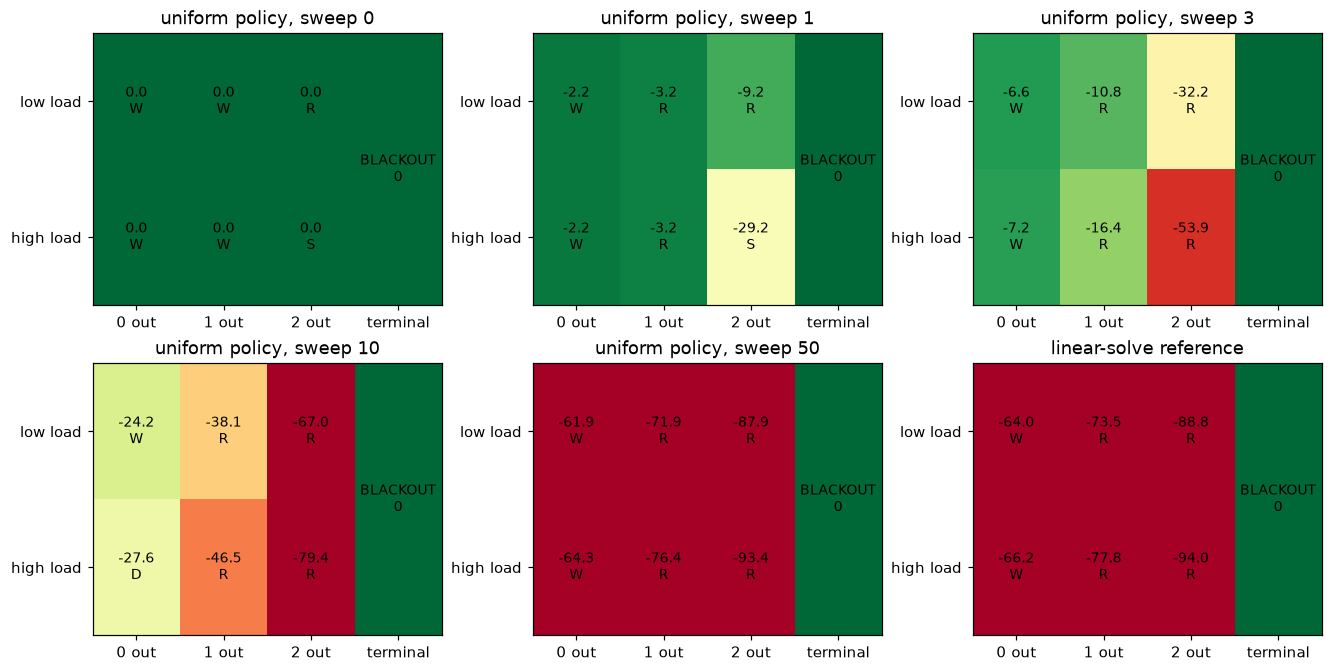

In [11]:
checkpoint_figure = new_figure(12.0, 6.0)
with Session(engine) as db:
    mdp = db.scalars(select(MDP).where(MDP.name == "main")).one()
    run = find_run(db, mdp, "uniform evaluation")
    for panel, requested in enumerate((0, 1, 3, 10, 50), start=1):
        sequence = min(requested, run.completed_sweeps)
        snapshot = db.scalars(select(Snapshot).where(Snapshot.run_id == run.id,
                                                     Snapshot.sequence == sequence)).one()
        greedify(db, run, snapshot)
        draw_snapshot(db, checkpoint_figure.add_subplot(2, 3, panel), snapshot, f"uniform policy, sweep {sequence}")
    reference_run = find_run(db, mdp, "uniform reference")
    reference = latest_snapshot(db, reference_run)
    greedify(db, reference_run, reference)
    draw_snapshot(db, checkpoint_figure.add_subplot(2, 3, 6), reference, "linear-solve reference")
    db.commit()
plt.show()

uniform: 299 sweeps to reach tolerance; final error=1.36e-08
always wait: 125 sweeps to reach tolerance; final error=4.54e-09


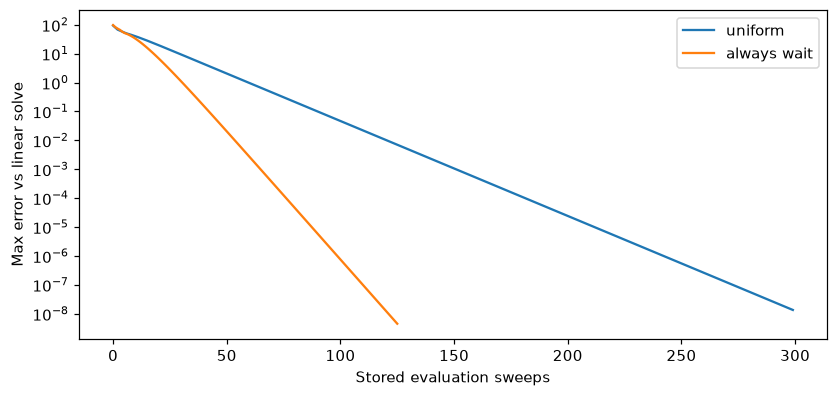

In [12]:
convergence_figure = new_figure(7.5, 3.5)
axis = convergence_figure.add_subplot(1, 1, 1)
with Session(engine) as db:
    mdp = db.scalars(select(MDP).where(MDP.name == "main")).one()
    for policy_name in ("uniform", "always wait"):
        run = find_run(db, mdp, f"{policy_name} evaluation")
        curve = error_query(db, run)
        axis.plot([x for x, _ in curve], [y for _, y in curve], label=policy_name)
        print(f"{policy_name}: {run.completed_sweeps} sweeps to reach tolerance; final error={curve[-1][1]:.2e}")
axis.set_yscale("symlog", linthresh=1e-10)
axis.set_xlabel("Stored evaluation sweeps")
axis.set_ylabel("Max error vs linear solve")
axis.legend()
plt.show()

## 5. Improvement and policy iteration

The lecture used Manhattan distance as an independent optimal-value reference; that shortcut only exists for
open Gridworlds. Here the independent reference is **value iteration** (repeated max-backups until the
optimality residual is below tolerance), which never constructs a policy.

In [13]:
def value_iteration(db: Session, run: Run) -> Snapshot:
    snapshot = initialize_values(db, run)
    for iteration in range(1, run.max_iterations + 1):
        run.iterations = iteration
        snapshot = backup(db, run, snapshot)
        assert snapshot.optimality_residual is not None
        if snapshot.optimality_residual <= run.tolerance:
            run.status = "converged"
            db.flush()
            return snapshot
    run.status = "failed"
    db.flush()
    raise RuntimeError("Value iteration exceeded its stored iteration limit.")


def count_policy_changes(db: Session, old: Policy, new: Policy) -> int:
    previous = aliased(PolicyProbability)
    differences = (
        select(PolicyProbability.state_id)
        .join(previous, (previous.state_id == PolicyProbability.state_id)
              & (previous.action_id == PolicyProbability.action_id))
        .where(PolicyProbability.policy_id == new.id, previous.policy_id == old.id)
        .where(func.abs(PolicyProbability.probability - previous.probability) > 1e-12)
        .group_by(PolicyProbability.state_id).subquery())
    return int(db.scalar(select(func.count()).select_from(differences)) or 0)


def policy_iteration(db: Session, run: Run) -> Snapshot:
    for iteration in range(1, run.max_iterations + 1):
        assert run.current_policy_id is not None
        policy = db.get(Policy, run.current_policy_id)
        assert policy is not None
        run.iterations = iteration
        snapshot = evaluate_exactly(db, run, policy)
        improved = greedify(db, run, snapshot)
        snapshot.changed_policy_states = count_policy_changes(db, policy, improved)
        run.current_policy_id = improved.id
        if snapshot.changed_policy_states == 0:
            assert snapshot.optimality_residual is not None
            if snapshot.optimality_residual > run.tolerance:
                raise RuntimeError("Policy is stable but its optimality residual is too large.")
            run.status = "converged"
            db.flush()
            return snapshot
    run.status = "failed"
    db.flush()
    raise RuntimeError("Policy iteration exceeded its stored iteration limit.")

In [14]:
with Session(engine) as db:
    mdp = db.scalars(select(MDP).where(MDP.name == "main")).one()
    vi_run = new_run(db, mdp, "value iteration", "value_iteration")
    optimal_snapshot = value_iteration(db, vi_run)
    greedify(db, vi_run, optimal_snapshot)

    random_snapshot = latest_snapshot(db, find_run(db, mdp, "uniform reference"))
    improved_policy = greedify(db, find_run(db, mdp, "uniform reference"), random_snapshot)
    improvement_run = new_run(db, mdp, "one improvement", "policy_improvement", improved_policy, optimal_snapshot)
    improved_snapshot = evaluate_exactly(db, improvement_run, improved_policy)
    greedify(db, improvement_run, improved_snapshot)
    improvement_run.status = "converged"

    uniform = db.scalars(select(Policy).where(Policy.mdp_id == mdp.id, Policy.name == "uniform")).one()
    pi_run = new_run(db, mdp, "policy iteration", "policy_iteration", uniform, optimal_snapshot)
    policy_iteration(db, pi_run)
    db.commit()
    print(f"value iteration: {vi_run.completed_sweeps} sweeps; policy iteration: {pi_run.iterations} iterations")

value iteration: 367 sweeps; policy iteration: 2 iterations


**Look for:** how much a single greedy improvement raises the random policy's values, and whether policy
iteration's final values match the independent value-iteration reference.

**Policy iteration history**

| iteration | states whose policy changed | optimality residual |
|---:|---:|---:|
| 1 | 6 | 7.37 |
| 2 | 0 | 7.11e-15 |

**State values by policy**

| state | always wait | uniform random | after 1 improvement | policy iteration | value iteration |
|---|---:|---:|---:|---:|---:|
| 0 out / low | -56.46 | -63.98 | -17.21 | -17.21 | -17.21 |
| 0 out / high | -62.87 | -66.20 | -19.33 | -19.33 | -19.33 |
| 1 out / low | -77.38 | -73.53 | -21.73 | -21.73 | -21.73 |
| 1 out / high | -83.81 | -77.79 | -26.84 | -26.84 | -26.84 |
| 2 out / low | -92.24 | -88.79 | -35.03 | -35.03 | -35.03 |
| 2 out / high | -97.59 | -93.96 | -52.74 | -52.74 | -52.74 |
| BLACKOUT | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 |

max |policy iteration - value iteration| = 1.75e-08


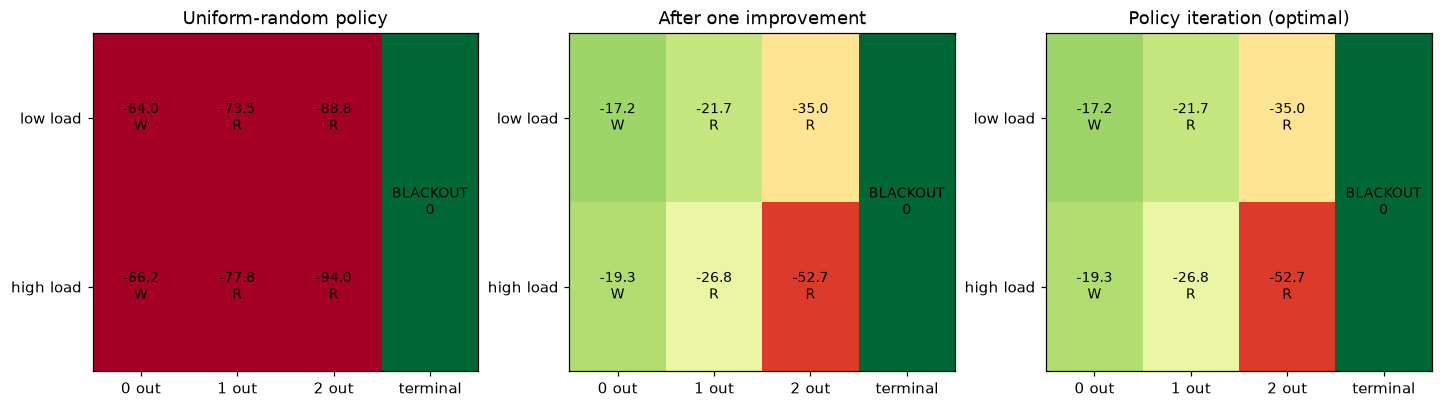

In [15]:
improvement_figure = new_figure(13.0, 3.6)
with Session(engine) as db:
    mdp = db.scalars(select(MDP).where(MDP.name == "main")).one()
    before = latest_snapshot(db, find_run(db, mdp, "uniform reference"))
    after = latest_snapshot(db, find_run(db, mdp, "one improvement"))
    final = latest_snapshot(db, find_run(db, mdp, "policy iteration"))
    draw_snapshot(db, improvement_figure.add_subplot(1, 3, 1), before, "Uniform-random policy")
    draw_snapshot(db, improvement_figure.add_subplot(1, 3, 2), after, "After one improvement")
    draw_snapshot(db, improvement_figure.add_subplot(1, 3, 3), final, "Policy iteration (optimal)")

    run = find_run(db, mdp, "policy iteration")
    lines = ["| iteration | states whose policy changed | optimality residual |", "|---:|---:|---:|"]
    for snap in db.scalars(select(Snapshot).where(Snapshot.run_id == run.id).order_by(Snapshot.sequence)):
        lines.append(f"| {snap.sequence + 1} | {snap.changed_policy_states} | {snap.optimality_residual:.3g} |")
    display(Markdown("**Policy iteration history**\n\n" + "\n".join(lines)))

    vi = values_by_label(db, latest_snapshot(db, find_run(db, mdp, "value iteration")))
    pi = values_by_label(db, final)
    rnd = values_by_label(db, before)
    wait = values_by_label(db, latest_snapshot(db, find_run(db, mdp, "always wait reference")))
    one = values_by_label(db, after)
    table = ["| state | always wait | uniform random | after 1 improvement | policy iteration | value iteration |",
             "|---|---:|---:|---:|---:|---:|"]
    for label in pi:
        table.append(f"| {label} | {wait[label]:.2f} | {rnd[label]:.2f} | {one[label]:.2f} | {pi[label]:.2f} | {vi[label]:.2f} |")
    display(Markdown("**State values by policy**\n\n" + "\n".join(table)))
    print("max |policy iteration - value iteration| =",
          f"{max(abs(pi[k] - vi[k]) for k in pi):.2e}")
plt.show()

## 6. Experiment: how the blackout penalty changes the optimal policy

A domain question the MDP can answer: **when is it worth paying for redispatch or load shedding?** We build
one MDP per blackout penalty in the same database (the schema supports many MDPs), run policy iteration on
each, and read the optimal action per state from SQL.

In [16]:
penalties = (-10.0, -50.0, -100.0, -300.0, -1000.0)
results: dict[float, dict[str, str]] = {}
with Session(engine) as db:
    for penalty in penalties:
        mdp = create_mdp(db, name=f"penalty {penalty:g}", blackout_penalty=penalty)
        validate_model(db, mdp)
        uniform = make_policy(db, mdp, "uniform")
        run = new_run(db, mdp, "policy iteration", "policy_iteration", uniform)
        snapshot = policy_iteration(db, run)
        greedy = snapshot.greedy_policy_id
        assert greedy is not None
        results[penalty] = {
            state.label: greedy_symbols(db, greedy, state.id)
            for state in db.scalars(select(State).where(State.mdp_id == mdp.id, ~State.is_terminal)
                                    .order_by(State.ordinal))
        }
    db.commit()

labels = list(next(iter(results.values())).keys())
header = "| state | " + " | ".join(f"penalty {p:g}" for p in penalties) + " |"
rows = [header, "|---|" + "---:|" * len(penalties)]
for label in labels:
    rows.append(f"| {label} | " + " | ".join(results[p][label] for p in penalties) + " |")
display(Markdown("**Optimal action per state** (W wait, R repair, D redispatch, S shed)\n\n" + "\n".join(rows)))

**Optimal action per state** (W wait, R repair, D redispatch, S shed)

| state | penalty -10 | penalty -50 | penalty -100 | penalty -300 | penalty -1000 |
|---|---:|---:|---:|---:|---:|
| 0 out / low | W | W | W | W | W |
| 0 out / high | W | W | W | W | D |
| 1 out / low | R | R | R | R | R |
| 1 out / high | R | R | R | R | S |
| 2 out / low | R | R | R | R | R |
| 2 out / high | W | R | R | S | S |

## Summary

* The **SQL schema** stores a stochastic MDP (one transition row per successor with its probability), and the
  same schema holds several MDPs, policies, runs and every value snapshot.
* **Policy evaluation**: iterative SQL backups converge geometrically (rate gamma) to the exact
  $(I-\gamma P_\pi)^{-1} r_\pi$ solution (299 sweeps for the uniform policy, 125 for always-wait at tolerance
  1e-9).
* **Policy improvement / iteration**: one greedy step from the uniform-random policy raises every state's value
  substantially (e.g. -63.98 to -17.21 in the calm state). In this small MDP that single step is already optimal:
  policy iteration stops after 2 iterations (the second changes no state), and its values match the independent
  value-iteration reference to about 2e-8.
* **Domain insight**: the optimal operator waits when the grid is healthy and repairs when a line is out. As the
  blackout penalty grows, it starts paying for redispatch and then load shedding in the most dangerous states.
  With a very small penalty (-10) it even stops repairing at `2 out / high`, because the expected repair cost
  outweighs the cheap blackout, a reminder that the reward design encodes the operator's priorities.